# Dataset Description and Exploratory Data Analysis

**Healthy Minds Study (HMS) 2024–2025 — Non-Clinical Depression/Anxiety Screening**

This notebook produces a **paper-ready dataset description and exploratory data analysis (EDA)** for the study.
It documents the source data, the cohort construction (inclusion criteria), the 25 predictor variables,
the screening target, missingness, univariate distributions, feature–target relationships, inter-feature
correlations, and the stratified train/validation/test split.

> **Ethical note.** The outcome `dep_or_anx` is a **screening signal derived from survey items**, not a
> clinical diagnosis. All records are de-identified. Feature associations are statistical and are **not**
> interpreted as causal.

**Contents**
1. Setup
2. Load raw dataset
3. Predictor schema (25 features)
4. Cohort construction (inclusion criteria)
5. Screening target distribution
6. Missingness analysis
7. Univariate feature distributions
8. Feature–target relationships
9. Inter-feature correlations
10. Stratified train/validation/test split
11. Paper-ready summary tables

## 1. Setup

Imports, plotting configuration, reproducibility seed, and output directory for paper figures/tables.

In [ ]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Paper-friendly plotting defaults
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

# Colour-blind-safe palette
PALETTE = ["#4E79A7", "#E15759", "#59A14F", "#F28E2B", "#B07AA1", "#76B7B2"]
POS_COLOR, NEG_COLOR = "#E15759", "#4E79A7"

RAW_CSV = Path("HMS_2024-2025_PUBLIC_instchars.csv")
FIG_DIR = Path("paper_outputs/dataset_figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("Raw file present:", RAW_CSV.exists())
print("Figures will be written to:", FIG_DIR.resolve())

Raw file present: True
Figures will be written to: C:\Users\MossabBatal\Desktop\psychology_mas\paper_outputs\dataset_figures


## 2. Load raw dataset

The Healthy Minds Study (HMS) 2024–2025 public release is a large multi-institution survey of college
students. The raw export contains **1,608 survey columns**. For this study we retain a compact,
interpretable subset of **25 predictor variables** plus the binary screening target `dep_or_anx` and the
non-response survey weight `nrweight`.

In [ ]:
# 25 interpretable predictors grouped by construct
FEATURE_GROUPS = {
    "Demographics": ["age", "gender_male", "gender_female", "international"],
    "Financial stress": ["fincur", "finpast", "food_worry"],
    "Lifestyle / health behaviour": ["sleep_wknight", "sleep_wkend", "exerc"],
    "Social connectedness": ["belong1", "belong2", "lonely"],
    "Academic / wellbeing": ["aca_impa", "flourish", "positiveMH"],
    "Substance use": ["sub_any", "binge1pl", "smok_cig"],
    "Discrimination": ["discrim_race", "discrim_gender", "discrim_sexual"],
    "Institutional context": ["inst_type", "inst_size", "inst_public"],
}
FEATURES = [f for group in FEATURE_GROUPS.values() for f in group]
TARGET = "dep_or_anx"
WEIGHT = "nrweight"

usecols = FEATURES + [TARGET, WEIGHT, "Finished"]
raw = pd.read_csv(RAW_CSV, usecols=lambda c: c in usecols, low_memory=False)

print(f"Raw rows loaded: {len(raw):,}")
print(f"Predictors: {len(FEATURES)} | target: '{TARGET}' | weight: '{WEIGHT}'")
raw.head()

Raw rows loaded: 84,735
Predictors: 25 | target: 'dep_or_anx' | weight: 'nrweight'


,Finished,age,gender_male,gender_female,international,belong1,discrim_race,discrim_gender,discrim_sexual,aca_impa,...,flourish,positiveMH,sub_any,binge1pl,smok_cig,nrweight,belong2,inst_size,inst_type,inst_public
0,1,18,1.0,NaN,0.0,3.0,0.0,0.0,0.0,1.0,...,26.0,0.0,0.0,0.0,0.0,1.261616,NaN,4,3,1
1,0,19,NaN,1.0,0.0,3.0,0.0,0.0,0.0,2.0,...,32.0,0.0,NaN,0.0,NaN,0.651369,NaN,4,3,1
2,0,18,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,0.841751,NaN,4,3,1
3,1,18,NaN,1.0,0.0,5.0,0.0,0.0,0.0,2.0,...,47.0,0.0,0.0,0.0,0.0,0.651369,NaN,4,3,1
4,0,23,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,0.841751,NaN,4,3,1


## 3. Predictor schema (25 features)

The 25 predictors span eight theoretically motivated constructs known to relate to student mental health:
demographics, financial stress, lifestyle/health behaviour, social connectedness, academic impact and
wellbeing, substance use, experiences of discrimination, and institutional context. The table below is
suitable for a paper appendix.

In [ ]:
DESCRIPTIONS = {
    "age": "Respondent age (years)",
    "gender_male": "Identifies as male (0/1)",
    "gender_female": "Identifies as female (0/1)",
    "international": "International student (0/1)",
    "fincur": "Current financial situation (stress scale)",
    "finpast": "Financial situation growing up (stress scale)",
    "food_worry": "Worried about running out of food",
    "sleep_wknight": "Typical sleep on weeknights (hours)",
    "sleep_wkend": "Typical sleep on weekends (hours)",
    "exerc": "Exercise frequency",
    "belong1": "Sense of belonging on campus (item 1)",
    "belong2": "Sense of belonging on campus (item 2)",
    "lonely": "Self-reported loneliness",
    "aca_impa": "Academic impairment due to mental/emotional difficulties",
    "flourish": "Flourishing scale (psychological wellbeing)",
    "positiveMH": "Positive mental health index",
    "sub_any": "Any substance use (0/1)",
    "binge1pl": "One or more binge-drinking episodes",
    "smok_cig": "Cigarette smoking",
    "discrim_race": "Experienced racial discrimination",
    "discrim_gender": "Experienced gender discrimination",
    "discrim_sexual": "Experienced sexual-orientation discrimination",
    "inst_type": "Institution type",
    "inst_size": "Institution size",
    "inst_public": "Public institution (0/1)",
}

rows = []
for group, feats in FEATURE_GROUPS.items():
    for f in feats:
        s = pd.to_numeric(raw[f], errors="coerce")
        rows.append({
            "Construct": group,
            "Variable": f,
            "Description": DESCRIPTIONS.get(f, ""),
            "Type": "binary" if set(s.dropna().unique()).issubset({0, 1}) else "numeric",
            "Missing %": round(raw[f].isna().mean() * 100, 1),
        })
schema = pd.DataFrame(rows)
schema.to_csv(FIG_DIR / "feature_schema.csv", index=False)
schema

,Construct,Variable,Description,Type,Missing %
0,Demographics,age,Respondent age (years),numeric,0.0
1,Demographics,gender_male,Identifies as male (0/1),binary,72.3
2,Demographics,gender_female,Identifies as female (0/1),binary,33.4
3,Demographics,international,International student (0/1),binary,1.8
4,Financial stress,fincur,Current financial situation (stress scale),numeric,6.4
5,Financial stress,finpast,Financial situation growing up (stress scale),numeric,6.5
6,Financial stress,food_worry,Worried about running out of food,numeric,6.8
7,Lifestyle / health behaviour,sleep_wknight,Typical sleep on weeknights (hours),numeric,60.7
8,Lifestyle / health behaviour,sleep_wkend,Typical sleep on weekends (hours),numeric,60.7
9,Lifestyle / health behaviour,exerc,Exercise frequency,numeric,54.7


## 4. Cohort construction (inclusion criteria)

We derive the analysis cohort from the raw export with three transparent inclusion criteria:

1. **Completed survey** — retain records with `Finished == 1`.
2. **Valid screening label** — retain records with a non-missing binary `dep_or_anx`.
3. **Sufficient feature completeness** — retain records with at least **60%** of the 25 predictors present.

The waterfall below reports how each criterion reduces the sample, giving the final analytic cohort.

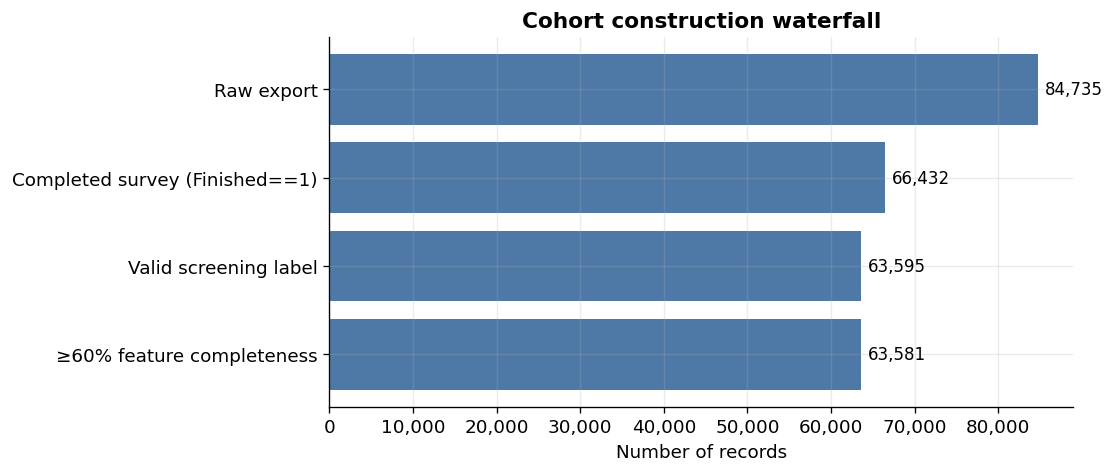

Final analytic cohort: 63,581 students


,Step,N records,Retained %,Dropped
0,Raw export,84735,100.0,0
1,Completed survey (Finished==1),66432,78.4,18303
2,Valid screening label,63595,75.1,2837
3,≥60% feature completeness,63581,75.0,14


In [ ]:
steps = []
df = raw.copy()
steps.append(("Raw export", len(df)))

# 1. Completed surveys
if "Finished" in df.columns:
    fin = pd.to_numeric(df["Finished"], errors="coerce")
    df = df[fin == 1]
steps.append(("Completed survey (Finished==1)", len(df)))

# 2. Valid binary target
df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")
df = df[df[TARGET].isin([0, 1])]
steps.append(("Valid screening label", len(df)))

# 3. >=60% feature completeness
completeness = df[FEATURES].notna().mean(axis=1)
df = df[completeness >= 0.60].reset_index(drop=True)
steps.append(("\u226560% feature completeness", len(df)))

for f in FEATURES:
    df[f] = pd.to_numeric(df[f], errors="coerce")
df[TARGET] = df[TARGET].astype(int)

waterfall = pd.DataFrame(steps, columns=["Step", "N records"])
waterfall["Retained %"] = (waterfall["N records"] / len(raw) * 100).round(1)
waterfall["Dropped"] = waterfall["N records"].diff().fillna(0).astype(int).abs()

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(waterfall["Step"], waterfall["N records"], color=PALETTE[0])
ax.invert_yaxis()
for b, n in zip(bars, waterfall["N records"]):
    ax.text(b.get_width() + len(raw) * 0.01, b.get_y() + b.get_height() / 2,
            f"{n:,}", va="center", fontsize=10)
ax.set_xlabel("Number of records")
ax.set_title("Cohort construction waterfall")
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
fig.savefig(FIG_DIR / "cohort_waterfall.png")
plt.show()

print(f"Final analytic cohort: {len(df):,} students")
waterfall

## 5. Screening target distribution

`dep_or_anx = 1` indicates an **elevated depression/anxiety screening signal** (positive screen). We report
the class balance, which is important context for the choice of evaluation metrics (e.g., AUC / balanced
accuracy) in the predictive modelling stage.

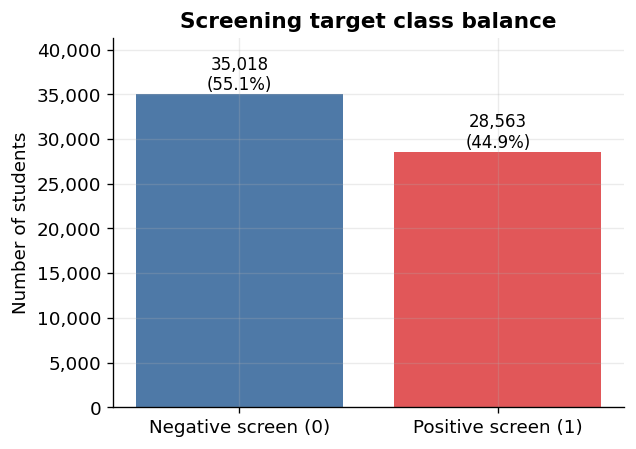

Positive-screen prevalence: 44.9%  (n=28,563)
Negative-screen prevalence: 55.1%  (n=35,018)


In [ ]:
counts = df[TARGET].value_counts().sort_index()
pct = df[TARGET].value_counts(normalize=True).sort_index() * 100
labels = ["Negative screen (0)", "Positive screen (1)"]

fig, ax = plt.subplots(figsize=(5.5, 4))
bars = ax.bar(labels, counts.values, color=[NEG_COLOR, POS_COLOR])
for b, n, p in zip(bars, counts.values, pct.values):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height(),
            f"{n:,}\n({p:.1f}%)", ha="center", va="bottom", fontsize=10)
ax.set_ylabel("Number of students")
ax.set_title("Screening target class balance")
ax.set_ylim(0, counts.max() * 1.18)
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
fig.savefig(FIG_DIR / "target_distribution.png")
plt.show()

print(f"Positive-screen prevalence: {pct.get(1, 0):.1f}%  (n={counts.get(1,0):,})")
print(f"Negative-screen prevalence: {pct.get(0, 0):.1f}%  (n={counts.get(0,0):,})")

## 6. Missingness analysis

Per-feature missingness in the analytic cohort. Remaining missing values are later handled by the model
pipeline (native missing-value handling / imputation). Features are sorted by missingness so reviewers can
quickly assess data quality.

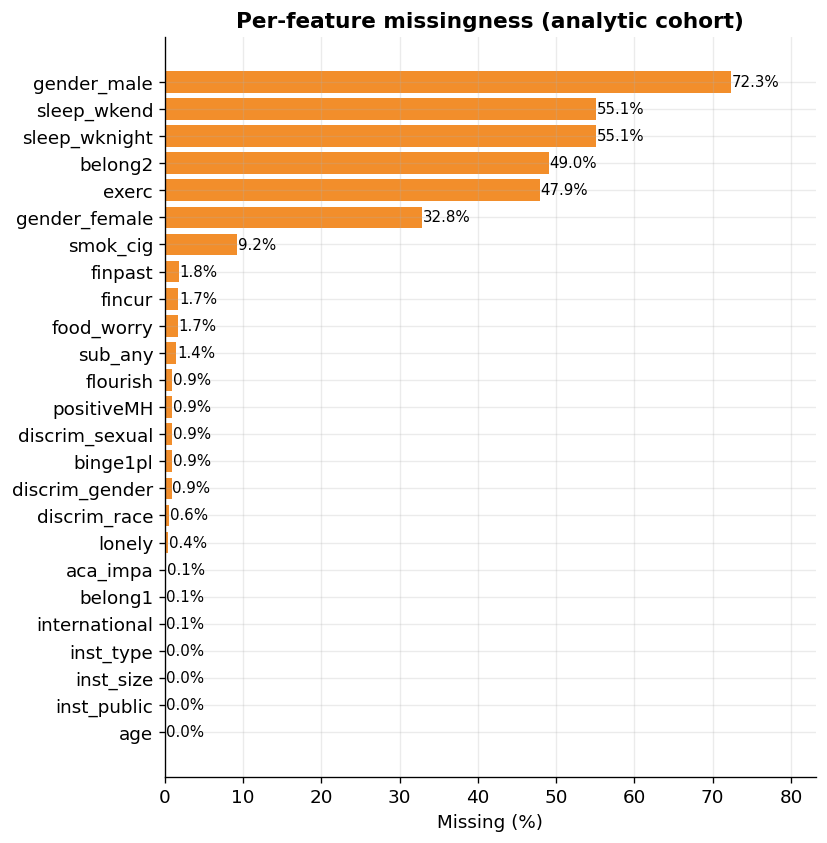

Mean missingness across features: 13.36%
Max missingness: 72.33% (gender_male)


In [ ]:
miss = (df[FEATURES].isna().mean() * 100).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(7, 8))
bars = ax.barh(miss.index, miss.values, color=PALETTE[3])
for b, v in zip(bars, miss.values):
    ax.text(b.get_width() + 0.1, b.get_y() + b.get_height() / 2,
            f"{v:.1f}%", va="center", fontsize=9)
ax.set_xlabel("Missing (%)")
ax.set_title("Per-feature missingness (analytic cohort)")
ax.set_xlim(0, max(miss.max() * 1.15, 1))
fig.savefig(FIG_DIR / "missingness.png")
plt.show()

print(f"Mean missingness across features: {miss.mean():.2f}%")
print(f"Max missingness: {miss.max():.2f}% ({miss.idxmax()})")

## 7. Univariate feature distributions

Descriptive statistics for all predictors, plus histograms for a representative set of continuous/ordinal
features. This characterises the scale and spread of each variable.

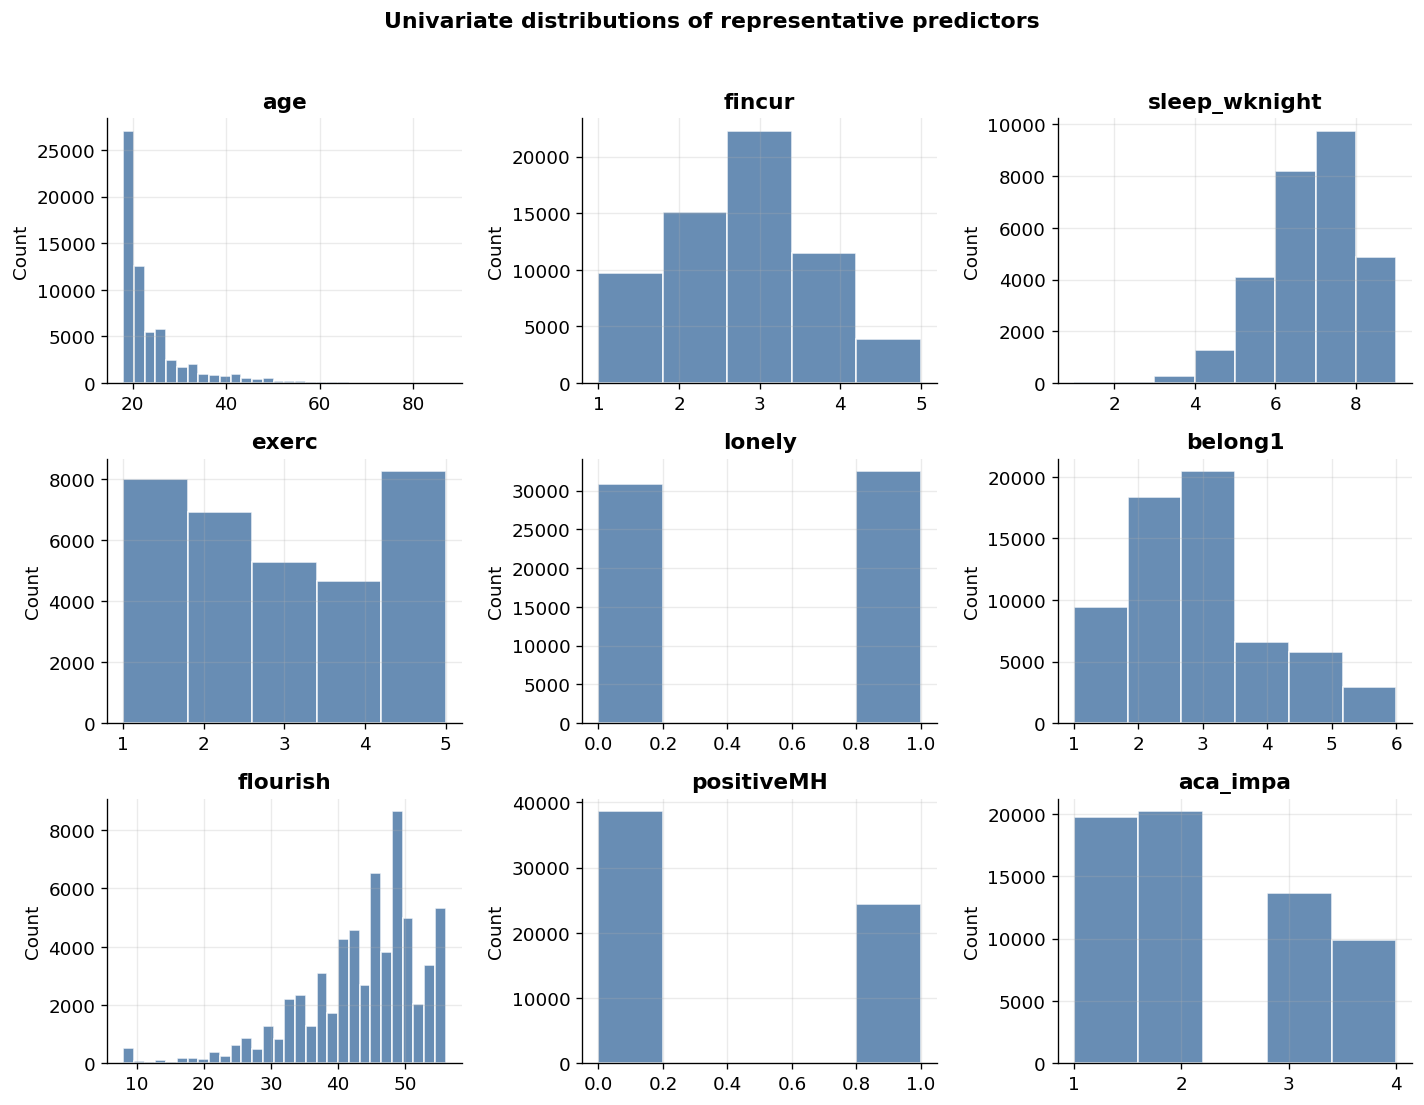

,Mean,SD,Min,Median,Max
age,24.22,8.29,18.0,21.0,87.0
gender_male,1.00,0.00,1.0,1.0,1.0
gender_female,1.00,0.00,1.0,1.0,1.0
international,0.09,0.28,0.0,0.0,1.0
fincur,2.76,1.11,1.0,3.0,5.0
finpast,3.11,1.26,1.0,3.0,5.0
food_worry,1.35,0.59,1.0,1.0,3.0
sleep_wknight,6.58,1.41,1.0,7.0,9.0
sleep_wkend,7.18,1.10,1.0,8.0,8.0
exerc,2.95,1.52,1.0,3.0,5.0


In [ ]:
desc = df[FEATURES].describe().T[["mean", "std", "min", "50%", "max"]]
desc.columns = ["Mean", "SD", "Min", "Median", "Max"]
desc = desc.round(2)
desc.to_csv(FIG_DIR / "feature_descriptives.csv")

# Histograms for a representative subset (continuous / multi-level ordinal)
subset = ["age", "fincur", "sleep_wknight", "exerc", "lonely",
          "belong1", "flourish", "positiveMH", "aca_impa"]
subset = [c for c in subset if c in df.columns]

n = len(subset)
ncols = 3
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows))
axes = np.array(axes).ravel()
for ax, col in zip(axes, subset):
    vals = df[col].dropna()
    nbins = min(30, max(5, vals.nunique()))
    ax.hist(vals, bins=nbins, color=PALETTE[0], edgecolor="white", alpha=0.85)
    ax.set_title(col)
    ax.set_ylabel("Count")
for ax in axes[n:]:
    ax.axis("off")
fig.suptitle("Univariate distributions of representative predictors", y=1.02, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "feature_distributions.png")
plt.show()

desc

## 8. Feature–target relationships

Standardised mean difference (Cohen's *d*) between the positive- and negative-screen groups for each
predictor. Positive values indicate the feature is higher in positively screened students; negative values
the opposite. This gives a model-agnostic view of which variables discriminate the screening outcome, and
contextualises the later SHAP-based explanations.

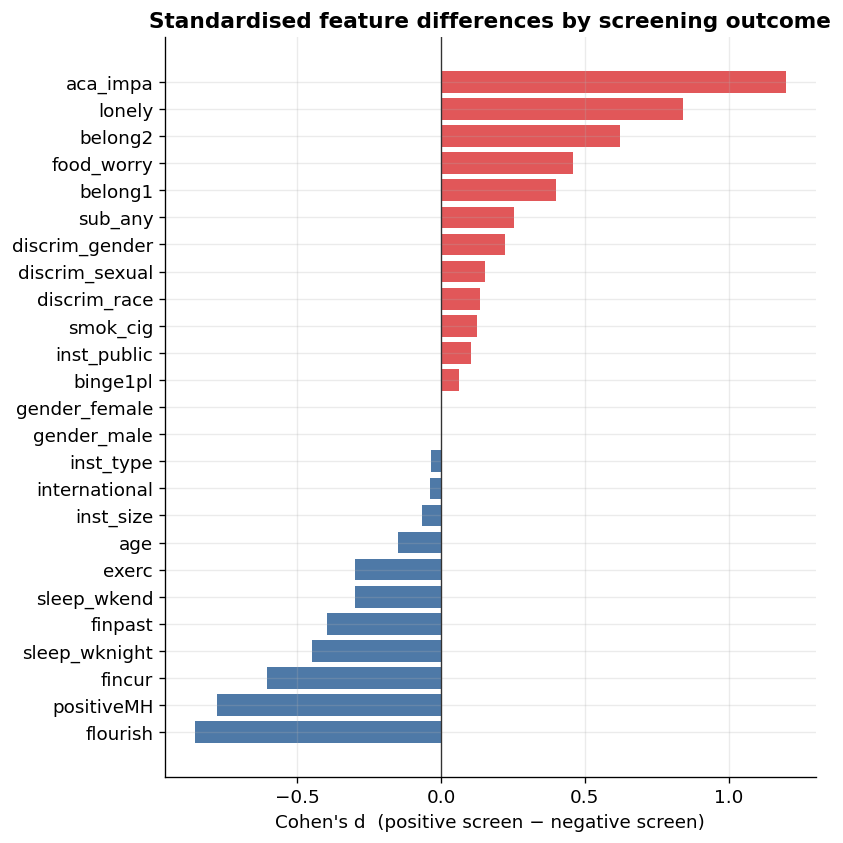

Strongest positive-screen associations:
belong1       0.398
food_worry    0.459
belong2       0.623
lonely        0.840
aca_impa      1.200

Strongest negative-screen (protective) associations:
flourish        -0.856
positiveMH      -0.778
fincur          -0.604
sleep_wknight   -0.447
finpast         -0.394


In [ ]:
def cohens_d(pos, neg):
    pos, neg = pos.dropna(), neg.dropna()
    n1, n2 = len(pos), len(neg)
    if n1 < 2 or n2 < 2:
        return np.nan
    s1, s2 = pos.std(ddof=1), neg.std(ddof=1)
    pooled = np.sqrt(((n1 - 1) * s1 ** 2 + (n2 - 1) * s2 ** 2) / (n1 + n2 - 2))
    if pooled == 0:
        return 0.0
    return (pos.mean() - neg.mean()) / pooled

pos_df = df[df[TARGET] == 1]
neg_df = df[df[TARGET] == 0]
effects = pd.Series({f: cohens_d(pos_df[f], neg_df[f]) for f in FEATURES}).sort_values()

fig, ax = plt.subplots(figsize=(7, 8))
colors = [POS_COLOR if v >= 0 else NEG_COLOR for v in effects.values]
ax.barh(effects.index, effects.values, color=colors)
ax.axvline(0, color="#333", linewidth=0.8)
ax.set_xlabel("Cohen's d  (positive screen \u2212 negative screen)")
ax.set_title("Standardised feature differences by screening outcome")
fig.savefig(FIG_DIR / "feature_target_effect_sizes.png")
plt.show()

eff_tbl = effects.rename("cohens_d").reset_index().rename(columns={"index": "feature"})
eff_tbl["cohens_d"] = eff_tbl["cohens_d"].round(3)
eff_tbl.to_csv(FIG_DIR / "feature_target_effect_sizes.csv", index=False)
print("Strongest positive-screen associations:")
print(effects.tail(5).round(3).to_string())
print("\nStrongest negative-screen (protective) associations:")
print(effects.head(5).round(3).to_string())

## 9. Inter-feature correlations

Pairwise Pearson correlations across predictors. Low overall multicollinearity supports the interpretability
of downstream feature-attribution (SHAP) analyses.

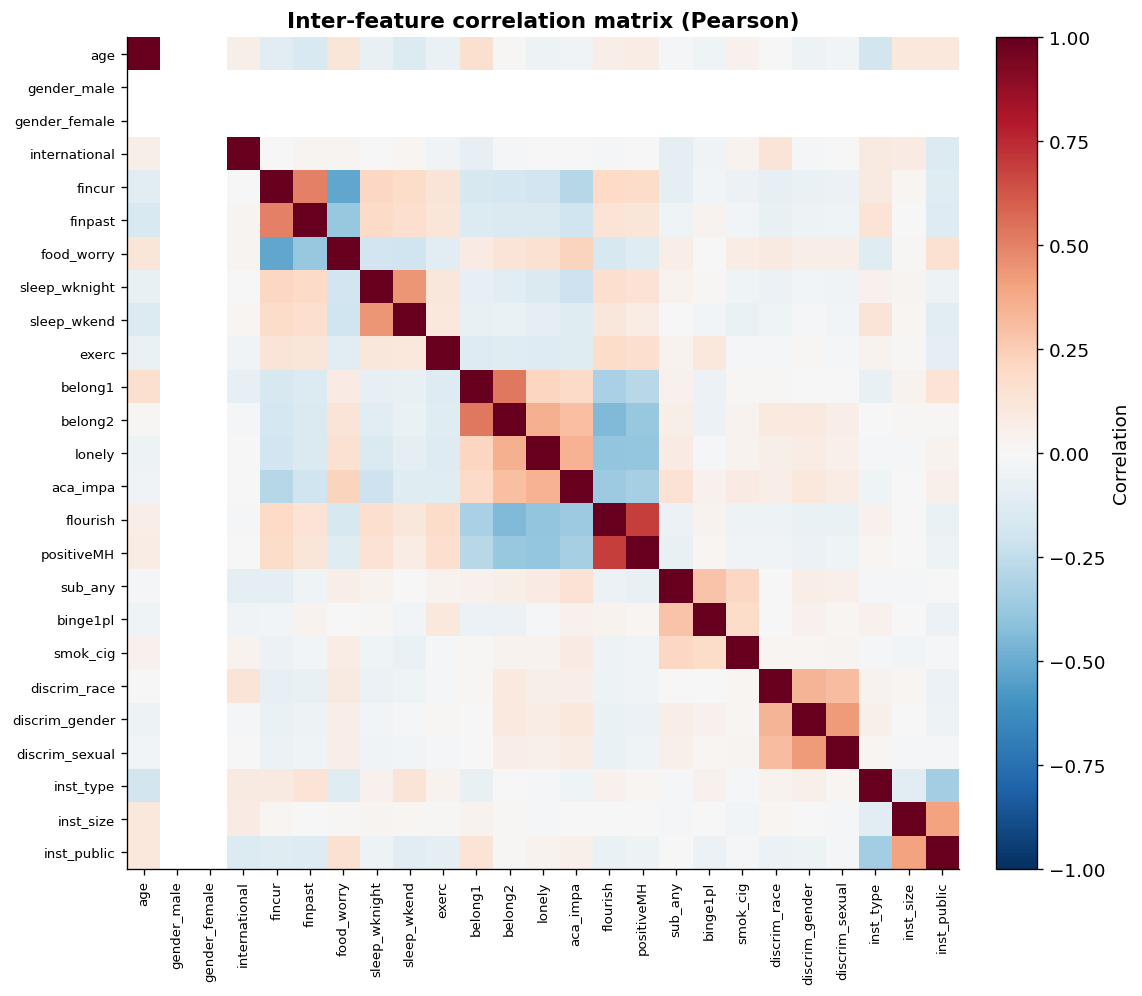

Strongest absolute correlations (|r|):
  positiveMH     ↔ flourish       r = +0.69
  belong1        ↔ belong2        r = +0.53
  food_worry     ↔ fincur         r = -0.52
  finpast        ↔ fincur         r = +0.51
  belong2        ↔ flourish       r = -0.44
  sleep_wknight  ↔ sleep_wkend    r = +0.44
  discrim_gender ↔ discrim_sexual r = +0.42
  inst_public    ↔ inst_size      r = +0.40


In [ ]:
corr = df[FEATURES].corr()

fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES)))
ax.set_yticks(range(len(FEATURES)))
ax.set_xticklabels(FEATURES, rotation=90, fontsize=8)
ax.set_yticklabels(FEATURES, fontsize=8)
ax.set_title("Inter-feature correlation matrix (Pearson)")
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Correlation")
ax.grid(False)
fig.savefig(FIG_DIR / "correlation_matrix.png")
plt.show()

# Highlight the strongest off-diagonal pairs
cm_vals = corr.abs().to_numpy(copy=True)
np.fill_diagonal(cm_vals, 0.0)
cm = pd.DataFrame(cm_vals, index=corr.index, columns=corr.columns)
pairs = (cm.unstack().sort_values(ascending=False)
         .drop_duplicates().head(8))
print("Strongest absolute correlations (|r|):")
for (a, b), v in pairs.items():
    print(f"  {a:<14} \u2194 {b:<14} r = {corr.loc[a, b]:+.2f}")

## 10. Stratified train/validation/test split

We partition the analytic cohort into **70% train / 15% validation / 15% test** using stratified sampling on
the screening target, preserving class balance across splits. This split is used by the predictive-modelling
and evaluation stages.

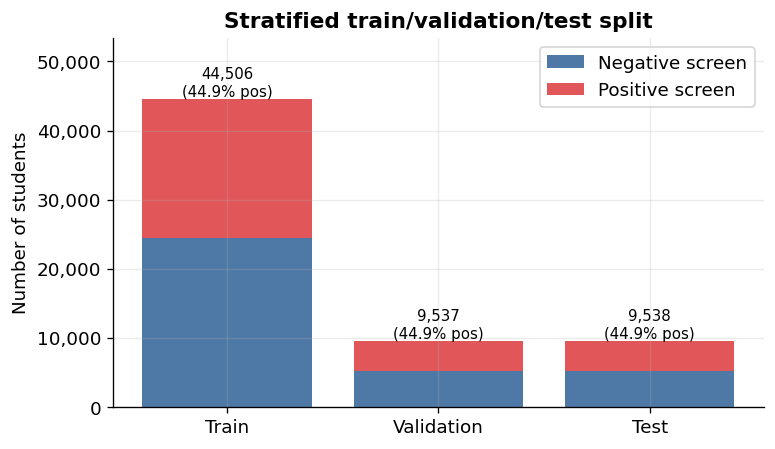

,Split,N,Positive %,Share %
0,Train,44506,44.9,70.0
1,Validation,9537,44.9,15.0
2,Test,9538,44.9,15.0
3,Total,63581,44.9,100.0


In [ ]:
from sklearn.model_selection import train_test_split

X = df[FEATURES]
y = df[TARGET]

X_train, X_tmp, y_train, y_tmp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE)
X_val, X_test, y_val, y_test = train_test_split(
    X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=RANDOM_STATE)

split_tbl = pd.DataFrame({
    "Split": ["Train", "Validation", "Test", "Total"],
    "N": [len(y_train), len(y_val), len(y_test), len(y)],
    "Positive %": [
        round(y_train.mean() * 100, 1),
        round(y_val.mean() * 100, 1),
        round(y_test.mean() * 100, 1),
        round(y.mean() * 100, 1),
    ],
})
split_tbl["Share %"] = (split_tbl["N"] / len(y) * 100).round(1)
split_tbl.loc[split_tbl["Split"] == "Total", "Share %"] = 100.0
split_tbl.to_csv(FIG_DIR / "split_summary.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 4))
sub = split_tbl[split_tbl["Split"] != "Total"]
neg = sub["N"] * (1 - sub["Positive %"] / 100)
pos = sub["N"] * (sub["Positive %"] / 100)
ax.bar(sub["Split"], neg, color=NEG_COLOR, label="Negative screen")
ax.bar(sub["Split"], pos, bottom=neg, color=POS_COLOR, label="Positive screen")
for i, (n, p) in enumerate(zip(sub["N"], sub["Positive %"])):
    ax.text(i, n, f"{n:,}\n({p:.1f}% pos)", ha="center", va="bottom", fontsize=9)
ax.set_ylabel("Number of students")
ax.set_title("Stratified train/validation/test split")
ax.set_ylim(0, sub["N"].max() * 1.2)
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.legend()
fig.savefig(FIG_DIR / "split_summary.png")
plt.show()

split_tbl

## 11. Paper-ready summary

Consolidated dataset facts and a ready-to-paste descriptive paragraph. All tables and figures are also saved
to `paper_outputs/dataset_figures/` (PNG at 300 dpi, CSV for tables) for direct inclusion in the manuscript.

In [ ]:
summary = pd.DataFrame({
    "Item": [
        "Data source",
        "Raw columns",
        "Raw records",
        "Analytic cohort (N)",
        "Predictors",
        "Constructs",
        "Screening target",
        "Positive-screen prevalence",
        "Mean feature missingness",
        "Train / Val / Test",
    ],
    "Value": [
        "Healthy Minds Study (HMS) 2024\u20132025 public release",
        f"{raw.shape[1]} loaded ({1608} in full export)",
        f"{len(raw):,}",
        f"{len(df):,}",
        f"{len(FEATURES)}",
        f"{len(FEATURE_GROUPS)}",
        "dep_or_anx (binary elevated screen)",
        f"{y.mean()*100:.1f}%",
        f"{miss.mean():.2f}%",
        f"{len(y_train):,} / {len(y_val):,} / {len(y_test):,}",
    ],
})
summary.to_csv(FIG_DIR / "dataset_summary.csv", index=False)

paragraph = (
    f"We analysed the Healthy Minds Study (HMS) 2024\u20132025 public release, a large multi-institution "
    f"survey of college students. From the raw export we retained {len(FEATURES)} interpretable predictors "
    f"spanning {len(FEATURE_GROUPS)} constructs (demographics, financial stress, lifestyle/health behaviour, "
    f"social connectedness, academic impact and wellbeing, substance use, discrimination, and institutional "
    f"context) together with a binary depression/anxiety screening outcome (dep_or_anx). After restricting to "
    f"completed surveys with a valid screening label and at least 60% feature completeness, the analytic "
    f"cohort comprised {len(df):,} students, of whom {y.mean()*100:.1f}% had an elevated screening signal. "
    f"Mean per-feature missingness was {miss.mean():.2f}%. The cohort was partitioned into stratified "
    f"training ({len(y_train):,}), validation ({len(y_val):,}), and test ({len(y_test):,}) sets, preserving "
    f"the class distribution. The screening outcome is a non-clinical survey-derived signal and is not a "
    f"diagnosis."
)

print(paragraph)
print("\nSaved artefacts in", FIG_DIR.resolve())
for p in sorted(FIG_DIR.glob("*")):
    print("  -", p.name)
summary

We analysed the Healthy Minds Study (HMS) 2024–2025 public release, a large multi-institution survey of college students. From the raw export we retained 25 interpretable predictors spanning 8 constructs (demographics, financial stress, lifestyle/health behaviour, social connectedness, academic impact and wellbeing, substance use, discrimination, and institutional context) together with a binary depression/anxiety screening outcome (dep_or_anx). After restricting to completed surveys with a valid screening label and at least 60% feature completeness, the analytic cohort comprised 63,581 students, of whom 44.9% had an elevated screening signal. Mean per-feature missingness was 13.36%. The cohort was partitioned into stratified training (44,506), validation (9,537), and test (9,538) sets, preserving the class distribution. The screening outcome is a non-clinical survey-derived signal and is not a diagnosis.

Saved artefacts in C:\Users\MossabBatal\Desktop\psychology_mas\paper_outputs\dat

,Item,Value
0,Data source,Healthy Minds Study (HMS) 2024–2025 public rel...
1,Raw columns,28 loaded (1608 in full export)
2,Raw records,"84,735"
3,Analytic cohort (N),"63,581"
4,Predictors,25
5,Constructs,8
6,Screening target,dep_or_anx (binary elevated screen)
7,Positive-screen prevalence,44.9%
8,Mean feature missingness,13.36%
9,Train / Val / Test,"44,506 / 9,537 / 9,538"
